# Voc Heads Detection

In [1]:
%pip install --no-deps ultralytics==8.3.0 
%pip install torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 881.3/881.3 kB 8.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import subprocess
import importlib.util

import json
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import shutil
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, nms, FrozenBatchNorm2d
from torchmetrics.detection import MeanAveragePrecision
import torchvision.transforms.functional as F
from torchvision.transforms import ColorJitter
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights,
    retinanet_resnet50_fpn_v2,
    RetinaNet_ResNet50_FPN_V2_Weights
)

from ultralytics import YOLO
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from functools import partial
import gc

SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

generator = torch.Generator()
generator.manual_seed(SEED)

print("PyTorch:", torch.__version__, "| устройство:", DEVICE)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.11.0+cu130 | устройство: cuda


## I. Dataset Exploration

In [3]:
CLASS_NAMES = {
    1: 'person_head',
    2: 'bird_head',
    3: 'cat_head',
    4: 'dog_head',
    5: 'horse_head',
    6: 'sheep_head',
    7: 'cow_head'
}

In [4]:
DATA_ROOT = Path("/kaggle/input/datasets/ibezushko/voc-heads-detection-v1/voc_heads_detection_v1/")

TRAIN_IMAGES = DATA_ROOT / 'images/train'
VAL_IMAGES = DATA_ROOT / 'images/val'
TEST_IMAGES = DATA_ROOT / 'images/test'

TRAIN_ANN = DATA_ROOT / 'annotations/train.json'
VAL_ANN = DATA_ROOT / 'annotations/val.json'

with open(TRAIN_ANN) as f:
    train_data = json.load(f)

with open(VAL_ANN) as f:
    val_data = json.load(f)

print(f'train: {len(list((TRAIN_IMAGES).glob('*.jpg')))}')
print(f'val: {len(list((VAL_IMAGES).glob('*.jpg')))}')
print(f'test: {len(list((TEST_IMAGES).glob('*.jpg')))}')

train: 1050
val: 158
test: 210


In [5]:
train_image = Image.open(next((TRAIN_IMAGES).glob('*.jpg')))
print(f'image size: {train_image.size}')
print(f'image mode: {train_image.mode}')

image size: (512, 512)
image mode: RGB


In [6]:
def read_example(name, data=train_data, image_dir=TRAIN_IMAGES):
    image_info = next(img for img in data['images'] if img['file_name'] == name)

    with Image.open(image_dir / Path(name).name) as source:
        image = source.convert('RGB')

    annotations = [
        ann for ann in data['annotations']
        if ann['image_id'] == image_info['id']
    ]

    boxes = []
    labels = []

    for ann in annotations:
        x, y, w, h = ann['bbox']
        boxes.append([x, y, x + w, y + h])
        labels.append(ann['category_id'])

    target = {
        'boxes': torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        'labels': torch.tensor(labels, dtype=torch.int64)
    }

    return image, target


def draw_boxes(ax, boxes, labels=None, scores=None, color='tab:green'):
    colors = plt.cm.tab10.colors

    for i, (x1, y1, x2, y2) in enumerate(torch.as_tensor(boxes).cpu().tolist()):
        class_id = int(labels[i]) if labels is not None else None
        box_color = colors[(class_id - 1) % len(colors)] if class_id is not None else color

        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=box_color, linewidth=2
        ))

        if class_id is not None:
            text = CLASS_NAMES[class_id]
            if scores is not None:
                text += f' {float(scores[i]):.2f}'

            ax.annotate(
                text, (x1, y1),
                xytext=(2, -3 - 12 * (i % 3)),
                textcoords='offset points',
                va='top', color='white', fontsize=8,
                bbox=dict(facecolor=box_color, alpha=0.8, edgecolor='none')
            )

def image_tensor(image):
    return torch.from_numpy(np.array(image.convert('RGB'))).permute(2, 0, 1).float() / 255

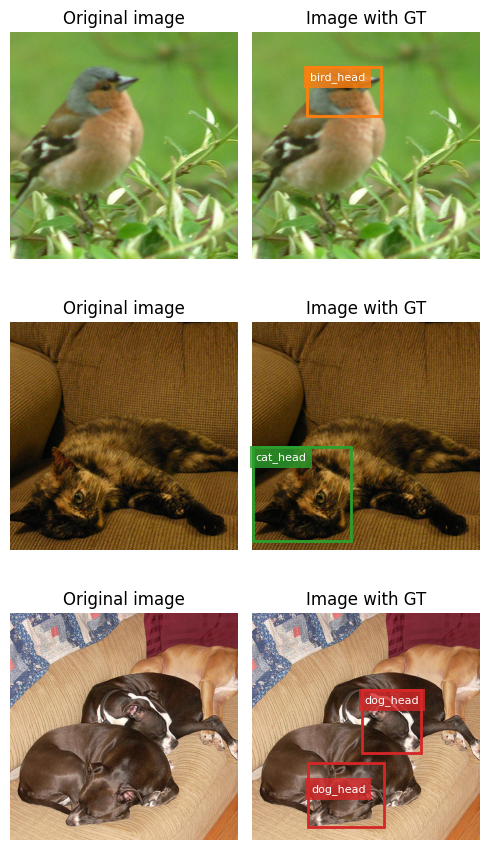

In [7]:
train_names = sorted(img['file_name'] for img in train_data['images'])

fig, axes = plt.subplots(3, 2, figsize=(5, 9))

for row, name in zip(axes, [train_names[i] for i in [8, 101, 550]]):
    image, target = read_example(name)

    row[0].imshow(image)
    row[1].imshow(image)

    draw_boxes(row[1], target['boxes'], target['labels'])

    for ax, title in zip(
        row,
        ['Original image', f'Image with GT']
    ):
        ax.set_title(title)
        ax.axis('off')

plt.tight_layout()
plt.show()

## II. Dataset & DataLoader

In [8]:
BATCH_SIZE = 4

In [9]:
class HeadsDataset(Dataset):
    def __init__(self, data, image_dir, augment=False):
        self.data = data
        self.image_dir = image_dir
        self.augment = augment
        self.names = [img['file_name'] for img in data['images']]

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        name = self.names[i]
        image, target = read_example(name, self.data, self.image_dir)

        image = np.array(image).astype(np.float32) / 255
        boxes = target['boxes'].clone()

        if self.augment:
            height, width = image.shape[:2]

            if np.random.rand() < 0.5:
                image = np.flip(image, axis=1).copy()

                boxes[:, 0] = width - target['boxes'][:, 2]
                boxes[:, 2] = width - target['boxes'][:, 0]

            if np.random.rand() < 0.5:
                brightness = np.random.uniform(-0.1, 0.1)
                image = np.clip(image + brightness, 0, 1)

            if np.random.rand() < 0.5:
                contrast = np.random.uniform(0.8, 1.2)
                mean = image.mean(axis=(0, 1), keepdims=True)
                image = np.clip((image - mean) * contrast + mean, 0, 1)

            if np.random.rand() < 0.3:
                saturation = np.random.uniform(0.8, 1.2)
                gray = image.mean(axis=2, keepdims=True)
                image = np.clip((image - gray) * saturation + gray, 0, 1)

        image = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float()
        target['boxes'] = boxes

        return image, target

In [10]:
def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = HeadsDataset(
    train_data,
    TRAIN_IMAGES,
    augment=True,
)

val_dataset = HeadsDataset(
    val_data,
    VAL_IMAGES,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=generator,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=True
)

In [11]:
print('train dataset:', len(train_dataset))
print('val dataset:', len(val_dataset))

print('train batches:', len(train_loader))
print('val batches:', len(val_loader))

train dataset: 1050
val dataset: 158
train batches: 263
val batches: 40


## III. Evaluation Metrics

In [12]:
@torch.no_grad()
def evaluate_metrics(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format='xyxy',
        iou_type='bbox',
        iou_thresholds=np.arange(0.5, 1.0, 0.05).tolist(),
        max_detection_thresholds=[1, 10, 100]
    )

    for images, targets in loader:
        images = [image.to(DEVICE) for image in images]

        predictions = model(images)

        predictions = [
            {
                'boxes': pred['boxes'].cpu(),
                'scores': pred['scores'].cpu(),
                'labels': pred['labels'].cpu()
            }
            for pred in predictions
        ]

        targets = [
            {
                'boxes': target['boxes'].cpu(),
                'labels': target['labels'].cpu()
            }
            for target in targets
        ]

        metric.update(predictions, targets)

    results = metric.compute()

    return {'mAP': results['map'].item()}

## IV. Model Architectures & Training

In [13]:
EPOCHS = 15
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 1e-4

In [14]:
NUM_CLASSES = len(CLASS_NAMES) + 1

def create_model(name, image_size=512):

    if name == 'fasterrcnn_mobilenet':
        model = fasterrcnn_mobilenet_v3_large_320_fpn(
            weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1
        )
        in_features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = FastRCNNPredictor(
            in_features,
            NUM_CLASSES
        )

    elif name == 'fasterrcnn_resnet50':
        model = fasterrcnn_resnet50_fpn_v2(
            weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
        )
        in_features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = FastRCNNPredictor(
            in_features,
            NUM_CLASSES
        )

    elif name == 'retinanet_resnet50':
        model = retinanet_resnet50_fpn_v2(
            weights=RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1
        )
        head = model.head.classification_head
        model.head.classification_head = RetinaNetClassificationHead(
            in_channels=head.conv[0][0].in_channels,
            num_anchors=head.num_anchors,
            num_classes=NUM_CLASSES,
            norm_layer=partial(nn.GroupNorm, 32)
        )

    elif name == 'yolov8s':
        model = YOLO('https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8s.pt')
        return model

    model.transform.min_size = (image_size,)
    model.transform.max_size = image_size

    return model.to(DEVICE)

In [15]:
def train_detector(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    epochs=EPOCHS,
    model_name='fasterrcnn_mobilenet'
):
    history = {
        'train_loss': [],
        'train_map': [],
        'val_loss': [],
        'val_map': [],
        'lr': []
    }

    best_map = -float('inf')
    best_path = f'/kaggle/working/best_{model_name}.pth'

    for epoch in range(epochs):

        model.train()

        train_total_loss = 0.

        for images, targets in train_loader:
            images = [image.to(DEVICE) for image in images]
            targets = [
                {key: value.to(DEVICE) for key, value in target.items()}
                for target in targets
            ]

            optimizer.zero_grad()

            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

            loss.backward()
            optimizer.step()

            train_total_loss += loss.item() * len(images)

        train_loss = train_total_loss / len(train_loader.dataset)
        history['train_loss'].append(train_loss)

        train_metrics = evaluate_metrics(model, train_loader)
        train_map = train_metrics['mAP']

        history['train_map'].append(train_map)

        model.train()

        val_total_loss = 0.

        with torch.no_grad():
            for images, targets in val_loader:
                images = [image.to(DEVICE) for image in images]
                targets = [
                    {key: value.to(DEVICE) for key, value in target.items()}
                    for target in targets
                ]

                loss_dict = model(images, targets)
                loss = sum(loss_dict.values())

                val_total_loss += loss.item() * len(images)

        val_loss = val_total_loss / len(val_loader.dataset)
        history['val_loss'].append(val_loss)

        val_metrics = evaluate_metrics(model, val_loader)
        val_map = val_metrics['mAP']

        history['val_map'].append(val_map)

        scheduler.step()

        current_lr = optimizer.param_groups[0]['lr']
        history['lr'].append(current_lr)

        if val_map > best_map:
            best_map = val_map
            torch.save(model.state_dict(), best_path)

        print(
            f'Epoch {epoch + 1:02d}/{epochs} | '
            f'Train Loss: {train_loss:.4f} | '
            f'Train mAP: {train_map:.4f} | '
            f'Val Loss: {val_loss:.4f} | '
            f'Val mAP: {val_map:.4f} | '
            f'Best mAP: {best_map:.4f} | '
            f'LR: {current_lr:.2e}'
        )

    model.load_state_dict(
        torch.load(best_path, map_location=DEVICE, weights_only=True)
    )

    return history

### i. Faster R-CNN MobileNetV3

In [16]:
MODEL_NAME = 'fasterrcnn_mobilenet'

fasterrcnn_mobilenet = create_model(MODEL_NAME, image_size=512)

optimizer_fasterrcnn_mobilenet = torch.optim.AdamW(
    fasterrcnn_mobilenet.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_fasterrcnn_mobilenet = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_fasterrcnn_mobilenet,
    T_max=EPOCHS
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 199MB/s]


In [17]:
history_fasterrcnn_mobilenet = train_detector(
    fasterrcnn_mobilenet,
    train_loader,
    val_loader,
    optimizer_fasterrcnn_mobilenet,
    scheduler_fasterrcnn_mobilenet,
    epochs=EPOCHS,
    model_name='fasterrcnn_mobilenet'
)

Epoch 01/15 | Train Loss: 0.9297 | Train mAP: 0.3118 | Val Loss: 0.9440 | Val mAP: 0.2916 | Best mAP: 0.2916 | LR: 2.97e-05
Epoch 02/15 | Train Loss: 0.9179 | Train mAP: 0.4761 | Val Loss: 0.9934 | Val mAP: 0.4031 | Best mAP: 0.4031 | LR: 2.87e-05
Epoch 03/15 | Train Loss: 0.8279 | Train mAP: 0.5393 | Val Loss: 1.0758 | Val mAP: 0.4308 | Best mAP: 0.4308 | LR: 2.71e-05
Epoch 04/15 | Train Loss: 0.8289 | Train mAP: 0.5599 | Val Loss: 0.9996 | Val mAP: 0.4137 | Best mAP: 0.4308 | LR: 2.50e-05
Epoch 05/15 | Train Loss: 0.7457 | Train mAP: 0.6373 | Val Loss: 1.0765 | Val mAP: 0.4607 | Best mAP: 0.4607 | LR: 2.25e-05
Epoch 06/15 | Train Loss: 0.6967 | Train mAP: 0.6633 | Val Loss: 1.0938 | Val mAP: 0.4516 | Best mAP: 0.4607 | LR: 1.96e-05
Epoch 07/15 | Train Loss: 0.6564 | Train mAP: 0.7080 | Val Loss: 1.1506 | Val mAP: 0.4882 | Best mAP: 0.4882 | LR: 1.66e-05
Epoch 08/15 | Train Loss: 0.6340 | Train mAP: 0.7312 | Val Loss: 1.1609 | Val mAP: 0.4646 | Best mAP: 0.4882 | LR: 1.34e-05
Epoch 09

### ii. Faster R-CNN ResNet50 FPN v2

In [18]:
MODEL_NAME = 'fasterrcnn_resnet50'

fasterrcnn_resnet50 = create_model(MODEL_NAME, image_size=512)

optimizer_fasterrcnn_resnet50 = torch.optim.AdamW(
    fasterrcnn_resnet50.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_fasterrcnn_resnet50 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_fasterrcnn_resnet50,
    T_max=EPOCHS
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 239MB/s] 


In [19]:
history_fasterrcnn_resnet50 = train_detector(
    fasterrcnn_resnet50,
    train_loader,
    val_loader,
    optimizer_fasterrcnn_resnet50,
    scheduler_fasterrcnn_resnet50,
    epochs=EPOCHS,
    model_name='fasterrcnn_resnet50'
)

Epoch 01/15 | Train Loss: 0.2956 | Train mAP: 0.4951 | Val Loss: 0.1677 | Val mAP: 0.4440 | Best mAP: 0.4440 | LR: 2.97e-05
Epoch 02/15 | Train Loss: 0.1422 | Train mAP: 0.5965 | Val Loss: 0.1364 | Val mAP: 0.5389 | Best mAP: 0.5389 | LR: 2.87e-05
Epoch 03/15 | Train Loss: 0.1083 | Train mAP: 0.6802 | Val Loss: 0.1320 | Val mAP: 0.5736 | Best mAP: 0.5736 | LR: 2.71e-05
Epoch 04/15 | Train Loss: 0.0890 | Train mAP: 0.7056 | Val Loss: 0.1204 | Val mAP: 0.5802 | Best mAP: 0.5802 | LR: 2.50e-05
Epoch 05/15 | Train Loss: 0.0778 | Train mAP: 0.7403 | Val Loss: 0.1419 | Val mAP: 0.5585 | Best mAP: 0.5802 | LR: 2.25e-05
Epoch 06/15 | Train Loss: 0.0648 | Train mAP: 0.7745 | Val Loss: 0.1360 | Val mAP: 0.5668 | Best mAP: 0.5802 | LR: 1.96e-05
Epoch 07/15 | Train Loss: 0.0586 | Train mAP: 0.8057 | Val Loss: 0.1310 | Val mAP: 0.5714 | Best mAP: 0.5802 | LR: 1.66e-05
Epoch 08/15 | Train Loss: 0.0485 | Train mAP: 0.8257 | Val Loss: 0.1262 | Val mAP: 0.6060 | Best mAP: 0.6060 | LR: 1.34e-05
Epoch 09

### iii. RetinaNet ResNet50 FPN v2

In [20]:
MODEL_NAME = 'retinanet_resnet50'

retinanet_resnet50 = create_model(MODEL_NAME, image_size=512)

optimizer_retinanet_resnet50 = torch.optim.AdamW(
    retinanet_resnet50.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_retinanet_resnet50 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_retinanet_resnet50,
    T_max=EPOCHS
)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 247MB/s] 


In [21]:
history_retinanet_resnet50 = train_detector(
    retinanet_resnet50,
    train_loader,
    val_loader,
    optimizer_retinanet_resnet50,
    scheduler_retinanet_resnet50,
    epochs=EPOCHS,
    model_name='retinanet_resnet50'
)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


Epoch 01/15 | Train Loss: 0.6627 | Train mAP: 0.4666 | Val Loss: 0.4614 | Val mAP: 0.4583 | Best mAP: 0.4583 | LR: 2.97e-05
Epoch 02/15 | Train Loss: 0.3840 | Train mAP: 0.6074 | Val Loss: 0.3822 | Val mAP: 0.5452 | Best mAP: 0.5452 | LR: 2.87e-05
Epoch 03/15 | Train Loss: 0.3195 | Train mAP: 0.6724 | Val Loss: 0.3556 | Val mAP: 0.5691 | Best mAP: 0.5691 | LR: 2.71e-05
Epoch 04/15 | Train Loss: 0.2582 | Train mAP: 0.7097 | Val Loss: 0.3389 | Val mAP: 0.5879 | Best mAP: 0.5879 | LR: 2.50e-05
Epoch 05/15 | Train Loss: 0.2175 | Train mAP: 0.7415 | Val Loss: 0.3296 | Val mAP: 0.5963 | Best mAP: 0.5963 | LR: 2.25e-05
Epoch 06/15 | Train Loss: 0.1908 | Train mAP: 0.7763 | Val Loss: 0.3153 | Val mAP: 0.6046 | Best mAP: 0.6046 | LR: 1.96e-05
Epoch 07/15 | Train Loss: 0.1627 | Train mAP: 0.7824 | Val Loss: 0.3156 | Val mAP: 0.6069 | Best mAP: 0.6069 | LR: 1.66e-05
Epoch 08/15 | Train Loss: 0.1495 | Train mAP: 0.8013 | Val Loss: 0.3245 | Val mAP: 0.6018 | Best mAP: 0.6069 | LR: 1.34e-05
Epoch 09

### iv. YOLOv8s

In [22]:
MODEL_NAME = 'yolov8s'

yolov8s = create_model(MODEL_NAME, image_size=512)

100%|██████████| 21.5M/21.5M [00:00<00:00, 230MB/s]


In [23]:
from collections import defaultdict

YOLO_ROOT = Path('/kaggle/working/voc_heads_yolo')

for split in ['train', 'val']:
    (YOLO_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)


def convert_to_yolo(data, image_dir, split):
    annotations = defaultdict(list)

    for ann in data['annotations']:
        annotations[ann['image_id']].append(ann)

    for image_info in data['images']:
        image_id = image_info['id']
        name = Path(image_info['file_name']).name

        width = image_info['width']
        height = image_info['height']

        source = image_dir / name
        destination = YOLO_ROOT / 'images' / split / name

        if not destination.exists():
            shutil.copy2(source, destination)

        lines = []

        for ann in annotations[image_id]:
            x, y, w, h = ann['bbox']

            class_id = ann['category_id'] - 1

            x_center = (x + w / 2) / width
            y_center = (y + h / 2) / height

            w /= width
            h /= height

            lines.append(
                f'{class_id} {x_center:.6f} {y_center:.6f} '
                f'{w:.6f} {h:.6f}'
            )

        label_path = YOLO_ROOT / 'labels' / split / f'{Path(name).stem}.txt'
        label_path.write_text('\n'.join(lines))


convert_to_yolo(train_data, TRAIN_IMAGES, 'train')
convert_to_yolo(val_data, VAL_IMAGES, 'val')

In [24]:
import yaml
config = {
    'path': str(YOLO_ROOT),
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        i - 1: name
        for i, name in CLASS_NAMES.items()
    }
}

YOLO_YAML = YOLO_ROOT / 'heads.yaml'

with open(YOLO_YAML, 'w') as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(YOLO_YAML)

/kaggle/working/voc_heads_yolo/heads.yaml


In [25]:
import ray.train._internal.session as ray_session

ray_session._get_session = lambda: None

In [26]:
yolo_results = yolov8s.train(
    data=str(YOLO_YAML),
    epochs=50,
    imgsz=600,
    batch=8,
    optimizer='AdamW',
    lr0=1e-4,
    weight_decay=1e-4,
    cos_lr=True,
    warmup_epochs=3,
    patience=30,
    close_mosaic=10,
    device=0 if torch.cuda.is_available() else 'cpu',
    seed=SEED,
    workers=2,
    project='voc_heads_models',
    name='yolov8s',
    exist_ok=True,
    plots=True
)

New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: task=detect, mode=train, model=weights/yolov8s.pt, data=/kaggle/working/voc_heads_yolo/heads.yaml, epochs=50, time=None, patience=30, batch=8, imgsz=600, save=True, save_period=-1, cache=False, device=0, workers=2, project=voc_heads_models, name=yolov8s, exist_ok=True, pretrained=True, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, emb

100%|██████████| 755k/755k [00:00<00:00, 30.9MB/s]
I0000 00:00:1795534278.406033      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Overriding model.yaml nc=80 with nc=7

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice:  3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


... (160 outputs left out)


50 epochs completed in 0.293 hours.
Optimizer stripped from voc_heads_models/yolov8s/weights/last.pt, 19.9MB
Optimizer stripped from voc_heads_models/yolov8s/weights/best.pt, 19.9MB

Validating voc_heads_models/yolov8s/weights/best.pt...
Ultralytics 8.3.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 186 layers, 9,830,373 parameters, 0 gradients


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:01<00:00,  5.84it/s]


                   all        158        159      0.846      0.837       0.88      0.632
           person_head         27         35      0.806      0.947      0.943      0.673
             bird_head         18         19      0.874      0.733      0.814      0.555
              cat_head         20         20       0.81       0.75      0.844      0.572
              dog_head         18         20      0.711       0.86      0.834      0.626
            horse_head         18         20      0.866      0.966      0.988      0.711
            sheep_head         18         23      0.935      0.696      0.809      0.527
              cow_head         18         22      0.917      0.909      0.929      0.759
Speed: 0.2ms preprocess, 4.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to voc_heads_models/yolov8s


lr/pg0,█▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr/pg1,▃▆██████▇▇▇▇▇▇▆▆▆▆▅▅▅▄▄▄▄▃▃▃▃▃▂▂▂▂▂▁▁▁▁▁
lr/pg2,▃▆█████▇▇▇▇▇▇▆▆▆▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁
metrics/mAP50(B),▁▃▄▅▅▆▆▇▇▇▇▇▇▇▇█▇██▇████████████████████
metrics/mAP50-95(B),▁▃▄▄▅▅▆▆▆▇▇▇▇▇▆▇▇██▇▇▇██████████████████
metrics/precision(B),▁▃▄▅▅▆▇▅▇▅▆▇▆▇▆▇▇▇▇▇▇▇█▇▇▇▇███▇▇▇▇▇▇▇▇█▇
metrics/recall(B),▂▁▃▄▅▆▅▅▆▆▇█▆▇▇▆▇▇▇█▇▆▇█▇▇███▇▇▇▇▇▇▇█▇▇█
model/GFLOPs,▁
model/parameters,▁
model/speed_PyTorch(ms),▁
+6,...


In [27]:
import pandas as pd

def get_yolo_history(results_path):
    df = pd.read_csv(results_path)
    df.columns = df.columns.str.strip()

    history = {
        'train_loss': (
            df['train/box_loss'] +
            df['train/cls_loss'] +
            df['train/dfl_loss']
        ).tolist(),

        'train_map': [None] * len(df),

        'val_loss': (
            df['val/box_loss'] +
            df['val/cls_loss'] +
            df['val/dfl_loss']
        ).tolist(),

        'val_map': df['metrics/mAP50-95(B)'].tolist(),

        'lr': df['lr/pg0'].tolist()
    }

    return history


history_yolov8s = get_yolo_history(
    '/kaggle/working/voc_heads_models/yolov8s/results.csv'
)

## V. Results & Visualization

In [28]:
def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    epochs = range(1, len(history['train_loss']) + 1)

    axes[0].plot(epochs, history['train_loss'], label='Train Loss')
    axes[0].plot(epochs, history['val_loss'], label='Validation Loss')
    axes[0].set_title(f'{model_name} — Training and Validation Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    if any(value is not None for value in history['train_map']):
        axes[1].plot(epochs, history['train_map'], label='Train mAP')

    axes[1].plot(epochs, history['val_map'], label='Validation mAP')
    axes[1].set_title(f'{model_name} — Training and Validation mAP')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('mAP@[0.5:0.95]')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [29]:
@torch.no_grad()
def predict_test(model, model_name, image):
    width, height = image.size

    if model_name == 'yolov8s':
        result = model.predict(
            source=np.array(image)[:, :, ::-1].copy(),
            imgsz=512,
            conf=0.001,
            iou=0.7,
            max_det=100,
            verbose=False
        )[0]

        boxes = result.boxes.xyxy.cpu()
        scores = result.boxes.conf.cpu()
        labels = result.boxes.cls.cpu().long() + 1

    else:
        tensor = image_tensor(image).to(DEVICE)

        prediction = model([tensor])[0]

        boxes = prediction['boxes'].cpu()
        scores = prediction['scores'].cpu()
        labels = prediction['labels'].cpu()

    valid = (
        (labels >= 1) &
        (labels <= len(CLASS_NAMES)) &
        torch.isfinite(boxes).all(dim=1) &
        torch.isfinite(scores)
    )

    boxes = boxes[valid]
    scores = scores[valid]
    labels = labels[valid]

    boxes[:, [0, 2]] = boxes[:, [0, 2]].clamp(0, width)
    boxes[:, [1, 3]] = boxes[:, [1, 3]].clamp(0, height)

    valid_boxes = (
        (boxes[:, 2] > boxes[:, 0]) &
        (boxes[:, 3] > boxes[:, 1])
    )

    boxes = boxes[valid_boxes]
    scores = scores[valid_boxes]
    labels = labels[valid_boxes]

    order = scores.argsort(descending=True)[:100]

    return boxes[order], scores[order], labels[order]

In [30]:
@torch.no_grad()
def visualize_predictions(model, model_name, indices=(8, 50, 100), score_threshold=0.3):
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))

    model.eval() if model_name != 'yolov8s' else None

    for row, idx in enumerate(indices):
        name = val_dataset.names[idx]

        image, target = read_example(
            name,
            val_data,
            VAL_IMAGES
        )

        boxes, scores, labels = predict_test(
            model,
            model_name,
            image
        )

        keep = scores >= score_threshold

        boxes = boxes[keep]
        scores = scores[keep]
        labels = labels[keep]

        axes[row, 0].imshow(image)

        axes[row, 1].imshow(image)
        draw_boxes(
            axes[row, 1],
            target['boxes'],
            target['labels']
        )

        axes[row, 2].imshow(image)
        draw_boxes(
            axes[row, 2],
            boxes,
            labels,
            scores
        )

        for col, title in enumerate([
            'Original',
            'Ground Truth',
            'Prediction'
        ]):
            axes[row, col].set_title(title)
            axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

### i. Faster R-CNN MobileNetV3

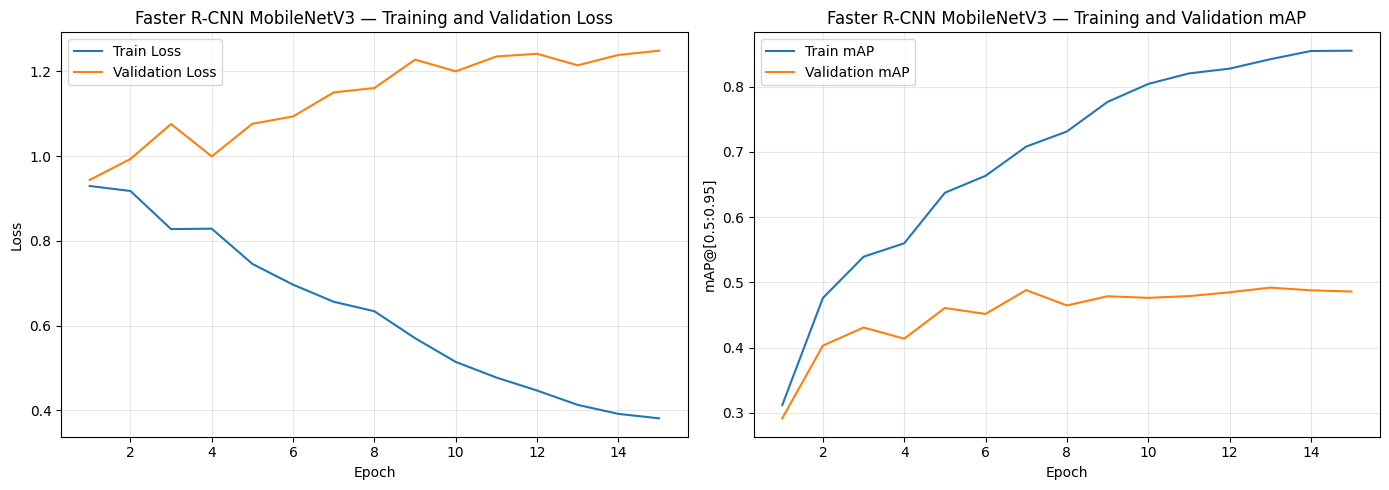

In [31]:
plot_training_history(history_fasterrcnn_mobilenet, 'Faster R-CNN MobileNetV3')

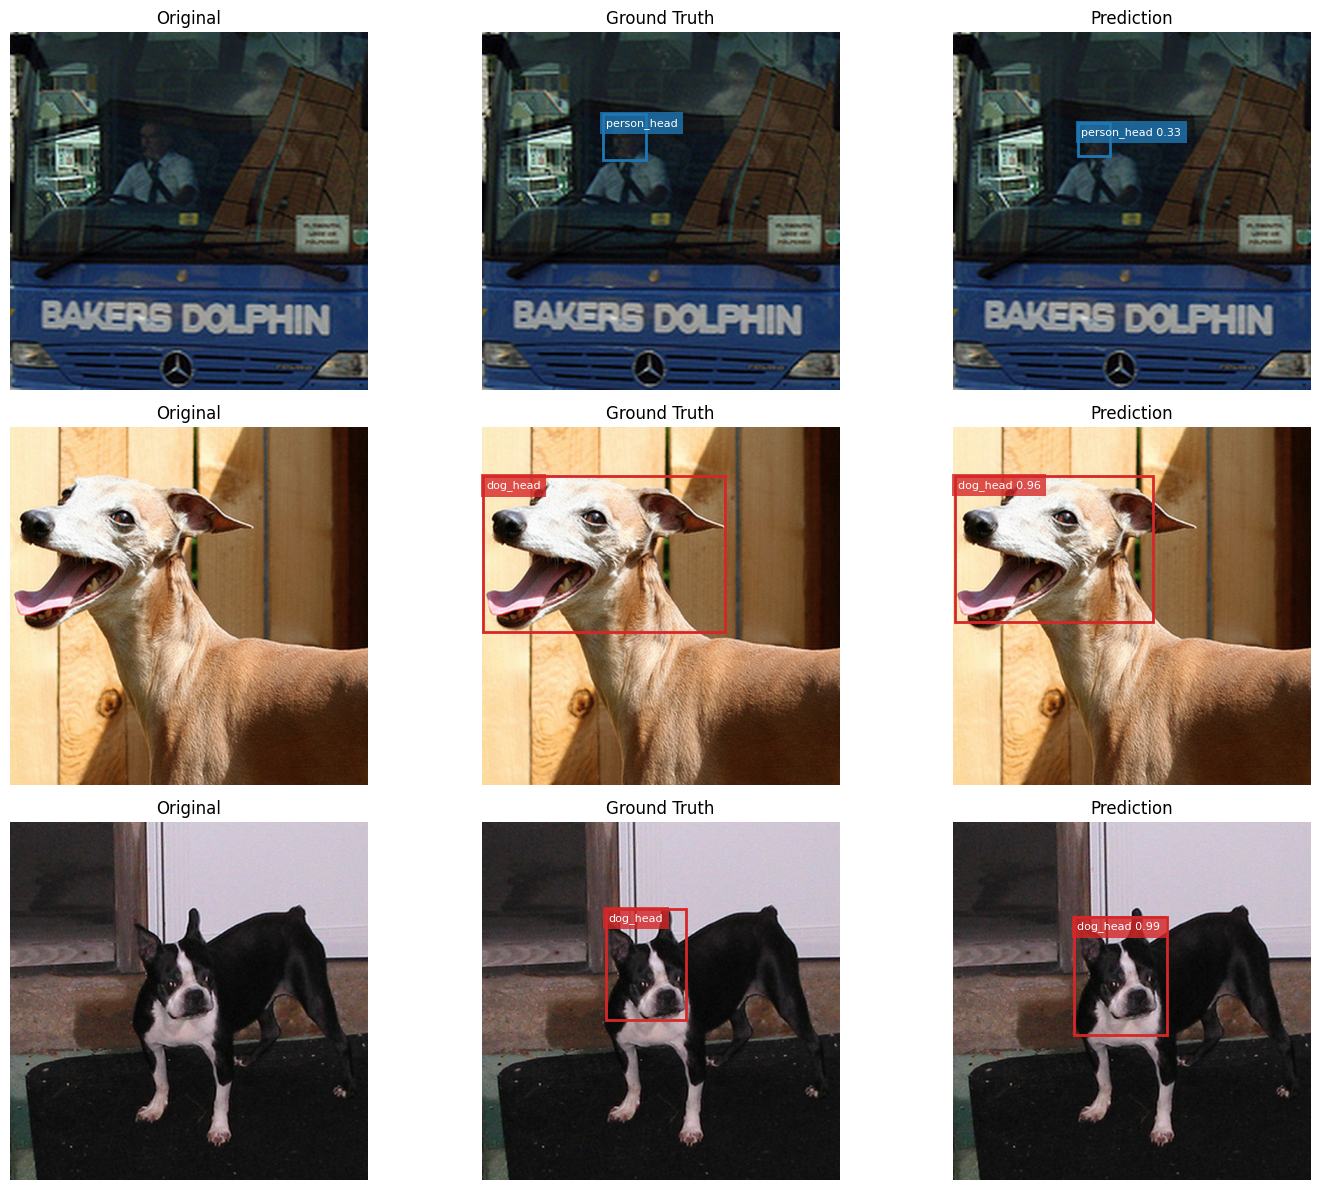

In [32]:
visualize_predictions(fasterrcnn_mobilenet, 'fasterrcnn_mobilenet')

### ii. Faster R-CNN ResNet50 FPN v2

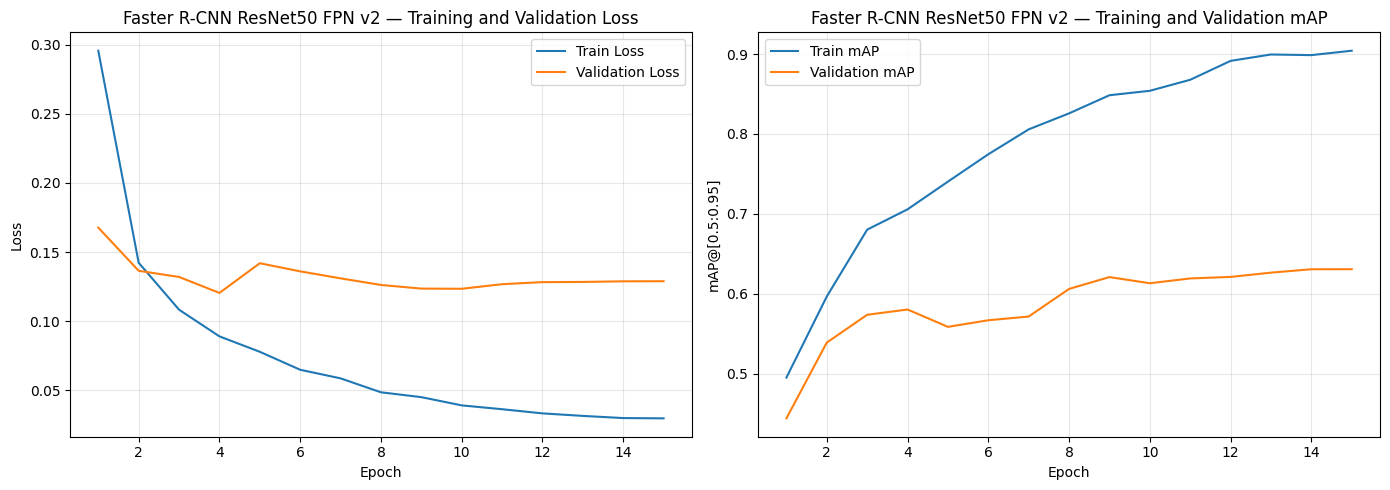

In [33]:
 plot_training_history(history_fasterrcnn_resnet50, 'Faster R-CNN ResNet50 FPN v2')

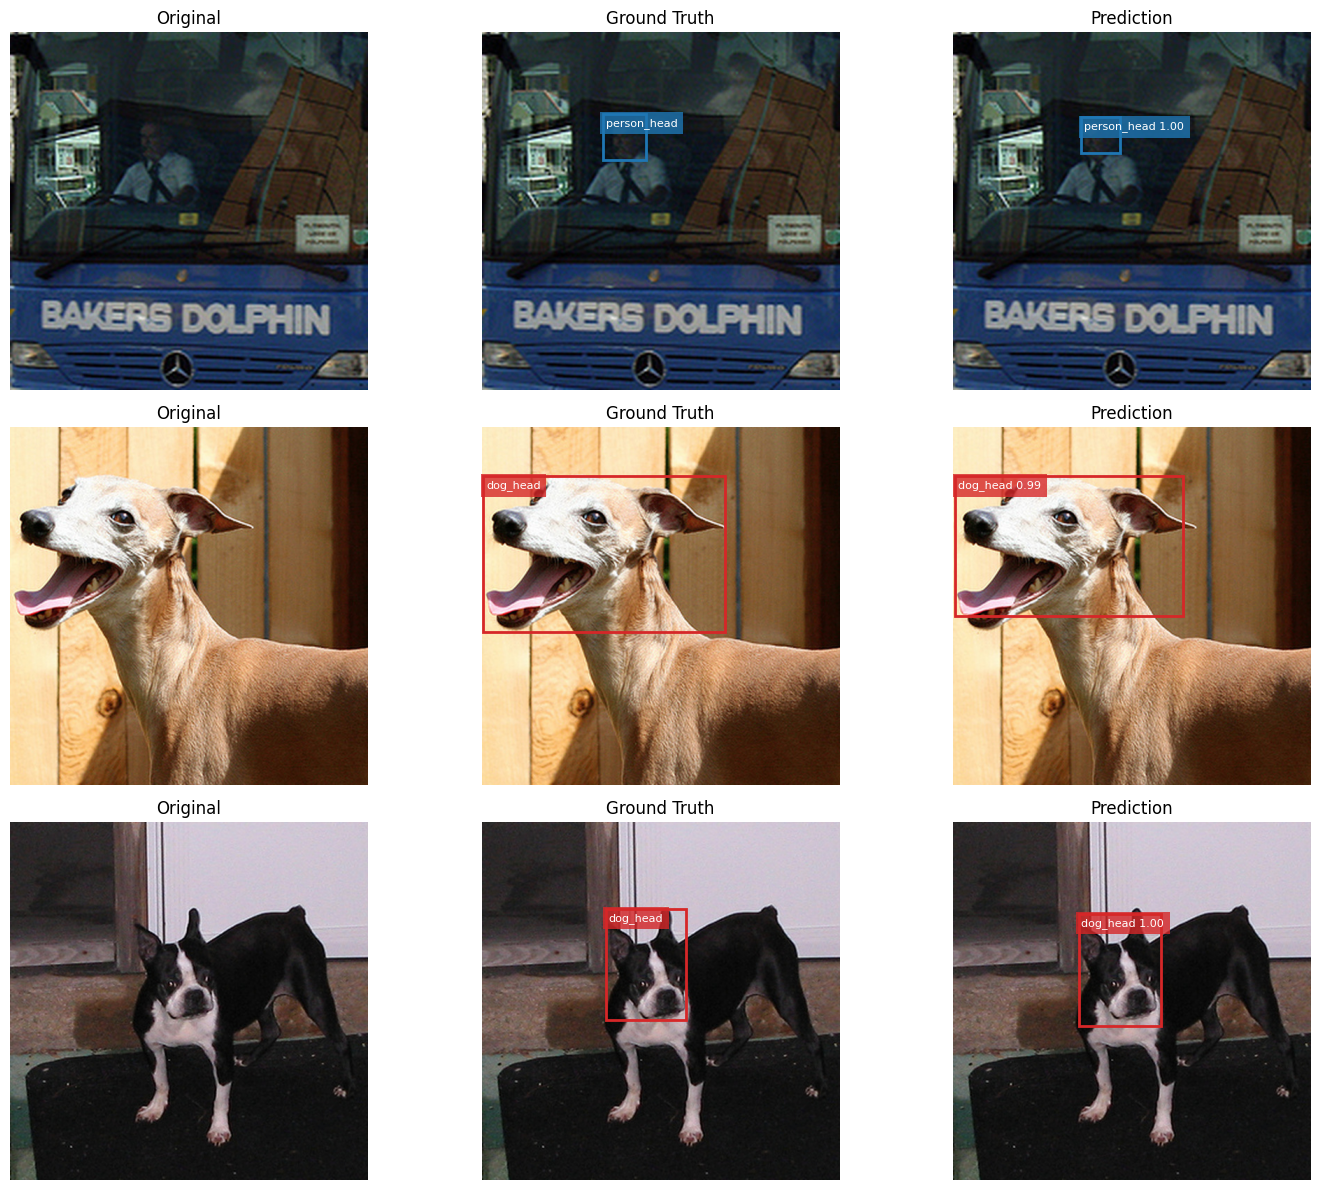

In [34]:
visualize_predictions(fasterrcnn_resnet50, 'fasterrcnn_resnet50')

### iii. RetinaNet ResNet50 FPN v2

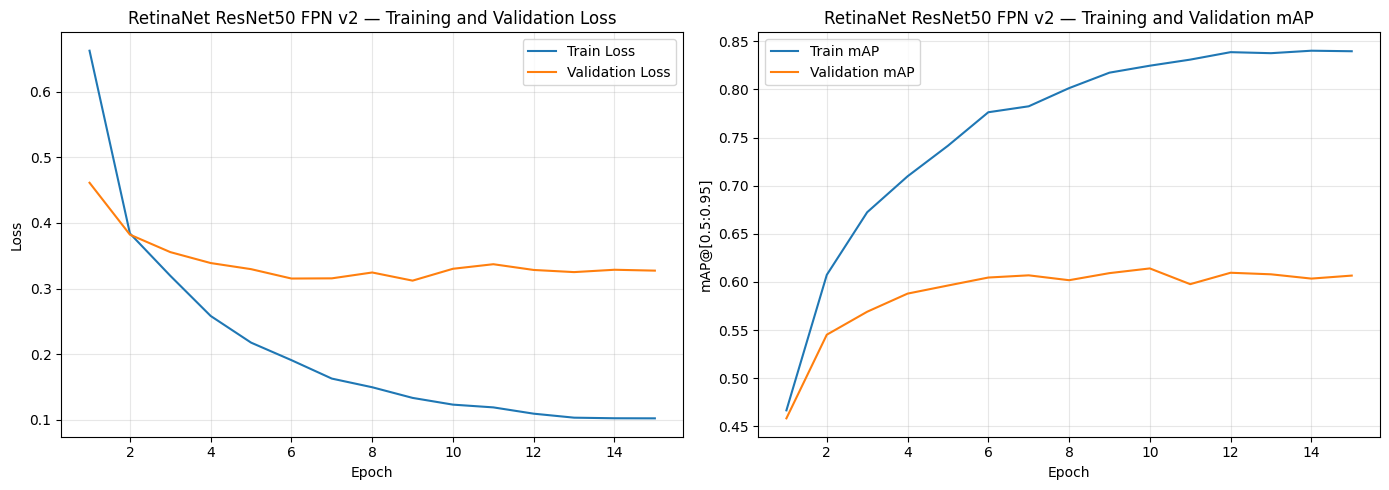

In [35]:
plot_training_history(history_retinanet_resnet50, 'RetinaNet ResNet50 FPN v2')

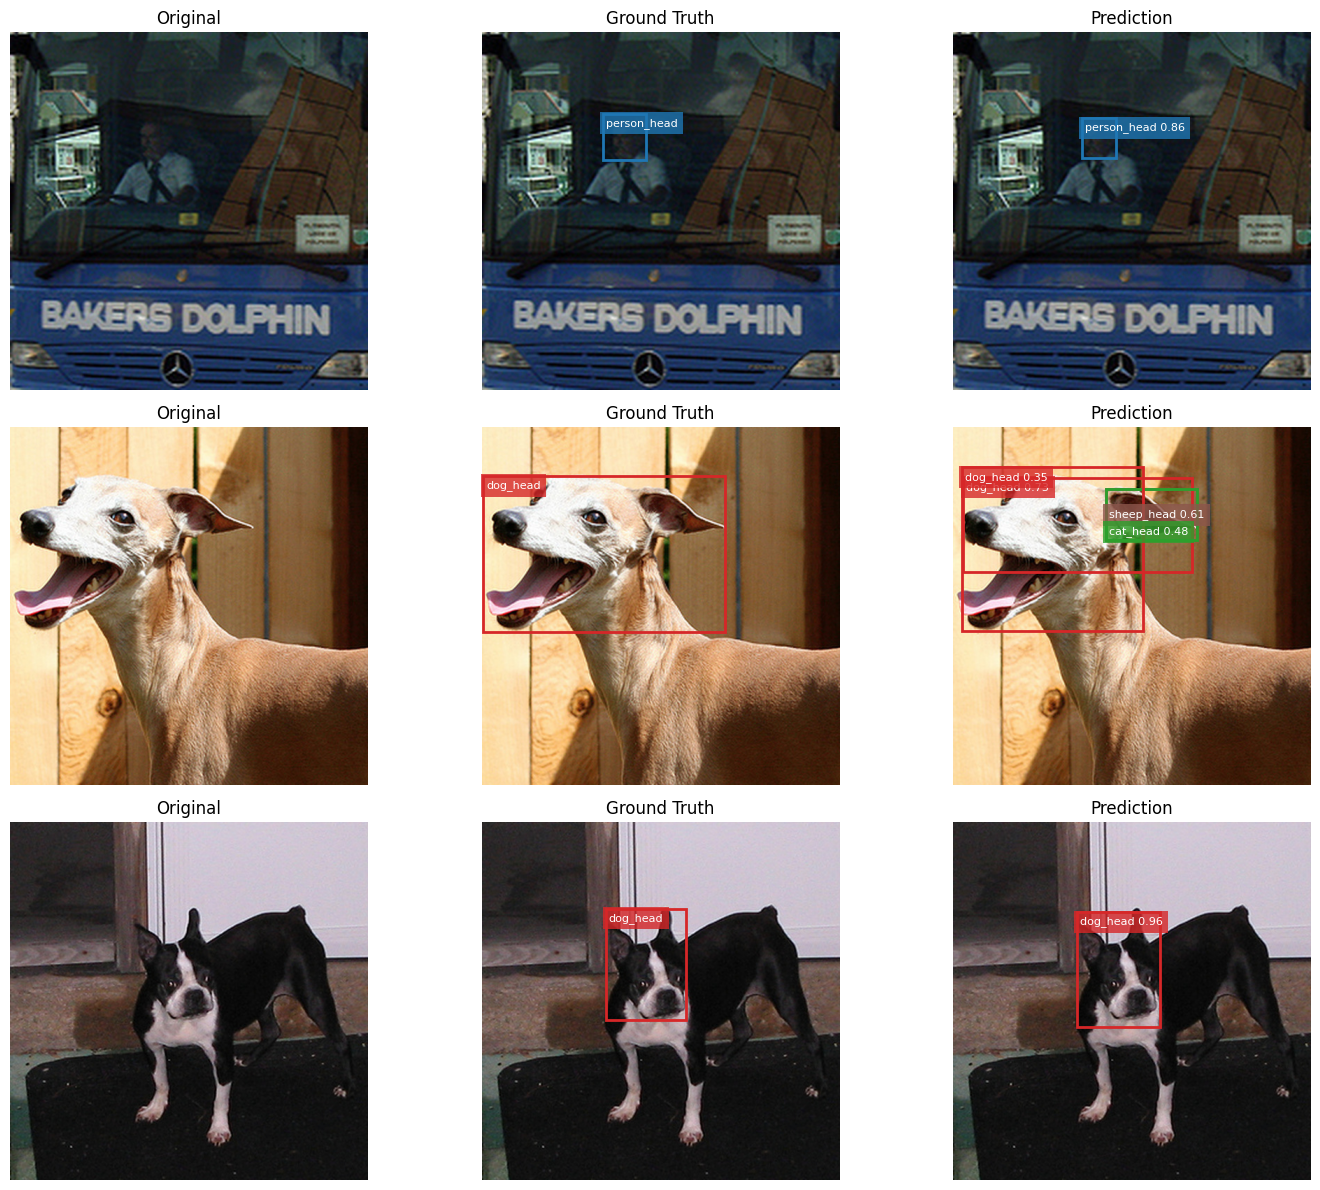

In [36]:
visualize_predictions(retinanet_resnet50, 'retinanet_resnet50')

### iv. YOLOv8s

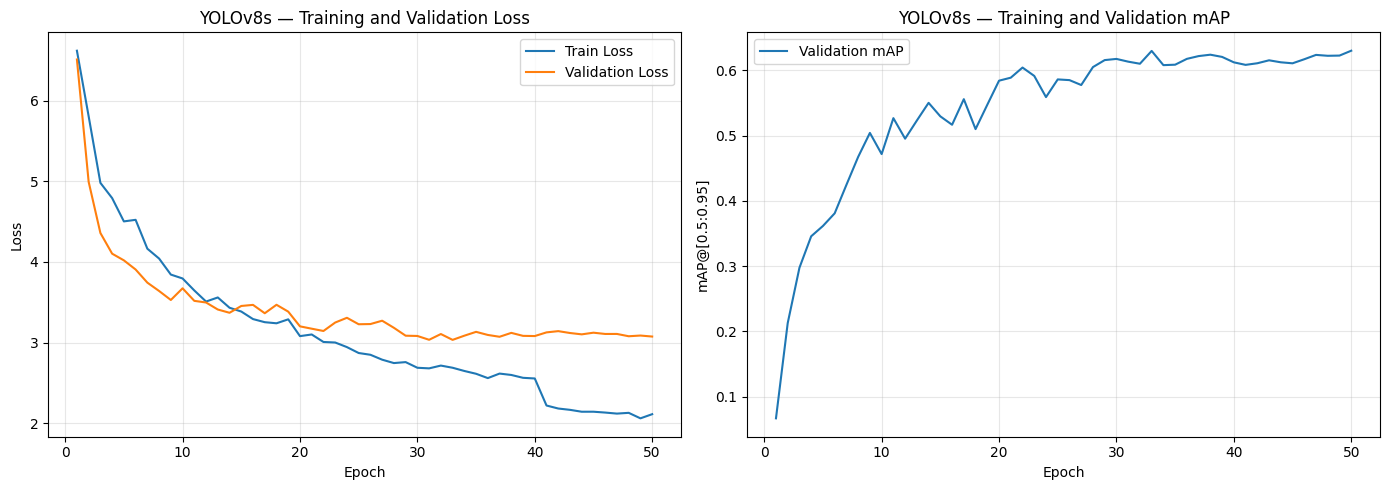

In [37]:
plot_training_history(history_yolov8s, 'YOLOv8s')

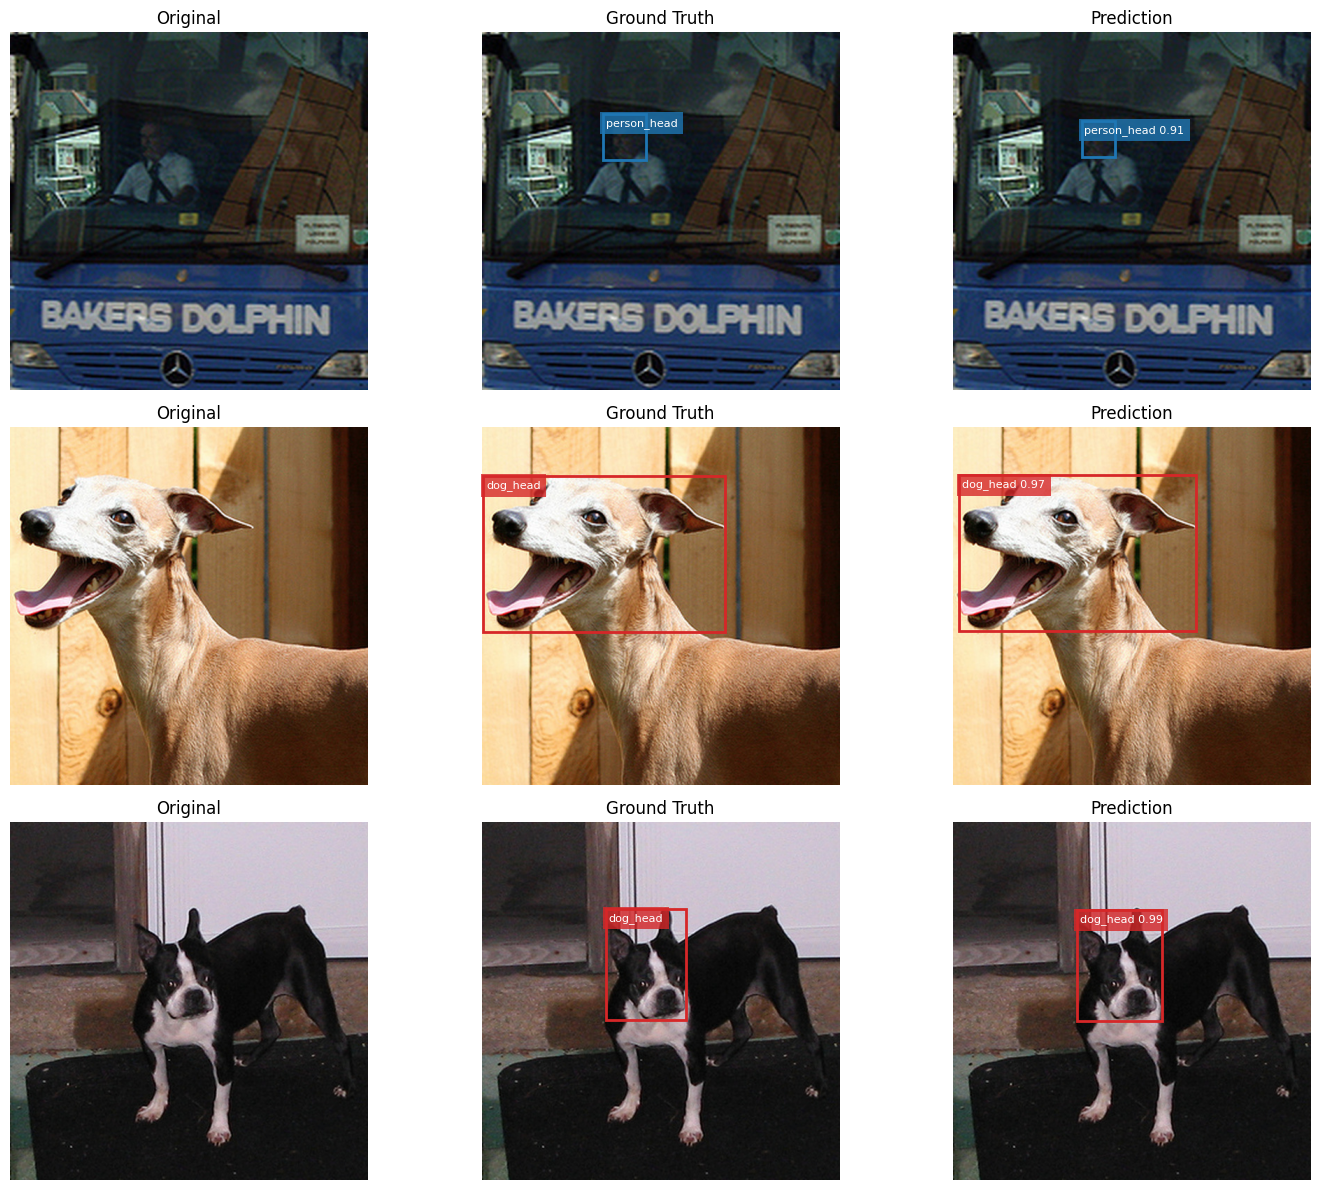

In [38]:
visualize_predictions(yolov8s, 'yolov8s')

### v. Model Comparison

In [39]:
histories = {
    'fasterrcnn_mobilenet': history_fasterrcnn_mobilenet,
    'fasterrcnn_resnet50': history_fasterrcnn_resnet50,
    'retinanet_resnet50': history_retinanet_resnet50,
    'yolov8s': history_yolov8s
}

comparison = []

for model_name, history in histories.items():
    val_map = np.array(history['val_map'])

    best_epoch = np.argmax(val_map) + 1
    best_map = np.max(val_map)

    comparison.append({
        'Model': model_name,
        'Best Epoch': best_epoch,
        'Best Val mAP': best_map
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    'Best Val mAP',
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Best Epoch,Best Val mAP
0,fasterrcnn_resnet50,15,0.6307
1,yolov8s,50,0.6302
2,retinanet_resnet50,10,0.6140
3,fasterrcnn_mobilenet,13,0.4919


## VI. Submission

In [40]:
best_model_name = max(
    histories,
    key=lambda name: max(histories[name]['val_map'])
)

print('Best model:', best_model_name)
print('Best Val mAP:', max(histories[best_model_name]['val_map']))

Best model: fasterrcnn_resnet50
Best Val mAP: 0.6306614279747009


In [41]:
if best_model_name == 'yolov8s':
    best_model = YOLO(
        '/kaggle/working/voc_heads_models/yolov8s/weights/best.pt'
    )
else:
    best_model = create_model(best_model_name, image_size=600)

    checkpoint = (
        f'/kaggle/working/best_{best_model_name}.pth'
    )

    best_model.load_state_dict(
        torch.load(checkpoint, map_location=DEVICE, weights_only=True)
    )

    best_model.eval()

In [42]:
submission = []

test_paths = sorted(TEST_IMAGES.glob('*.jpg'))

for image_path in test_paths:
    with Image.open(image_path) as source:
        image = source.convert('RGB')

    boxes, scores, labels = predict_test(
        best_model,
        best_model_name,
        image
    )

    predictions = []

    for box, score, label in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box.tolist()

        predictions.extend([
            str(int(label)),
            f'{float(score):.6f}',
            f'{x1:.2f}',
            f'{y1:.2f}',
            f'{x2:.2f}',
            f'{y2:.2f}'
        ])

    submission.append({
        'id': image_path.stem,
        'prediction_string': ' '.join(predictions)
    })

submission_df = pd.DataFrame(submission)

submission_path = 'submission.csv'
submission_df.to_csv(submission_path, index=False)


display(submission_df.head())

,id,prediction_string
0,test_01f25f383d2ee770,
1,test_026a5503b3376876,5 0.997206 335.92 20.18 469.04 236.38
2,test_06700c3b72230d31,7 0.995563 316.68 200.16 393.38 290.74
3,test_0a81e7350cbcaa89,6 0.183374 154.82 106.14 256.66 241.76
4,test_0c5010e4d995345a,5 0.987427 218.24 284.66 297.75 415.82
